# EN3160 Assignment 2 on Fitting and Alignment

##### Index No: 230476T
##### Name: Perera G.M.B.

https://github.com/maneth-b03p/Image_Processing_and_Machine_Vision_Activities.git

In [86]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

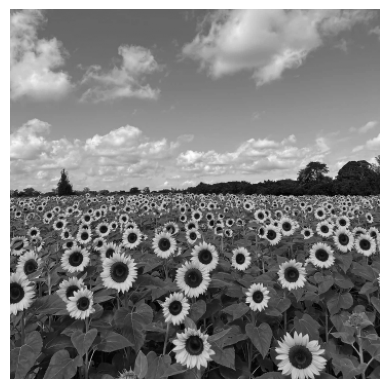

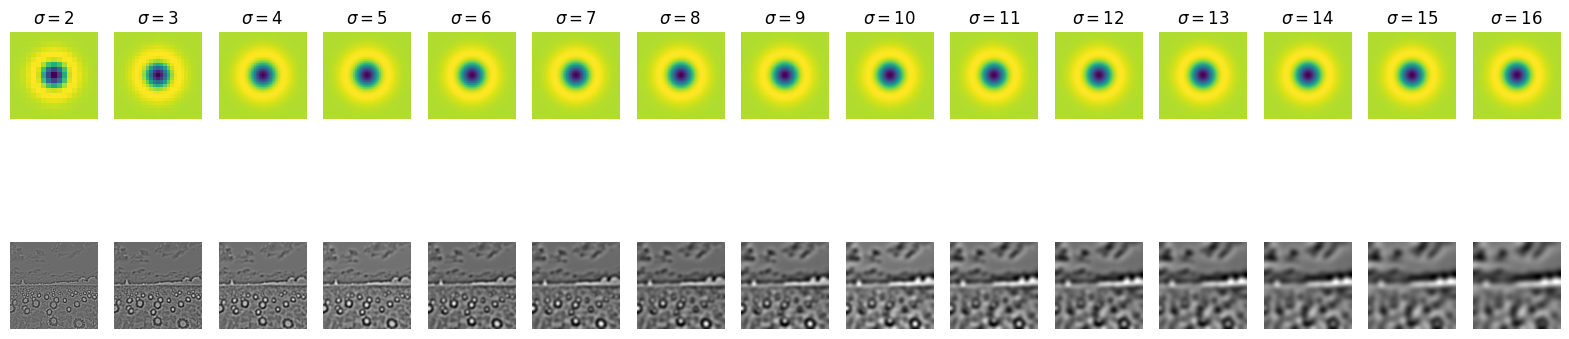

In [103]:
image_rgb = cv.imread('a2images/a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
image = cv.cvtColor(image_rgb, cv.COLOR_BGR2GRAY)

#sigma = 15

# image_gaussian = cv.GaussianBlur(image, (0, 0), sigmaX = sigma)
# laplacian_signed = cv.Laplacian(image_gaussian, cv.CV_16S, ksize=1)*sigma**2

# print(laplacian_signed)

plt.imshow(image, cmap = "gray")
plt.axis("off")
plt.show()

h,w = image.shape
min_sig = 2
s = 15
fig, ax = plt.subplots(2, s, figsize=(20,5))
scale_space = np.empty((h, w, s), dtype=np.float32)
sigmas = np.arange(min_sig, min_sig+s , 1)
for i, sigma in enumerate(sigmas):
    log_hw = 4*np.max(sigma)
    X, Y = np.meshgrid(np.arange(-log_hw, log_hw + 1, 1), np.arange(-log_hw, log_hw + 1, 1))
    log = 1/(2*np.pi*sigma**2)*(X**2/(sigma**2) + Y**2/(sigma**2) - 2)*np.exp(-(X**2 + Y**2)/(2*sigma**2))
    f_log = cv.filter2D(image, cv.CV_32F, log)
    scale_space[:, :, i] = f_log
    ax[0, i].imshow(log)
    ax[0, i].axis('off')
    ax[0, i].set_title(r'$\sigma = {}$'.format(sigma))    
    ax[1, i].imshow(f_log, cmap = "gray")
    ax[1, i].axis('off')

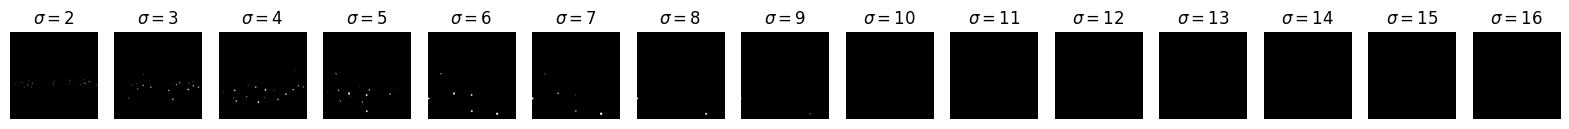

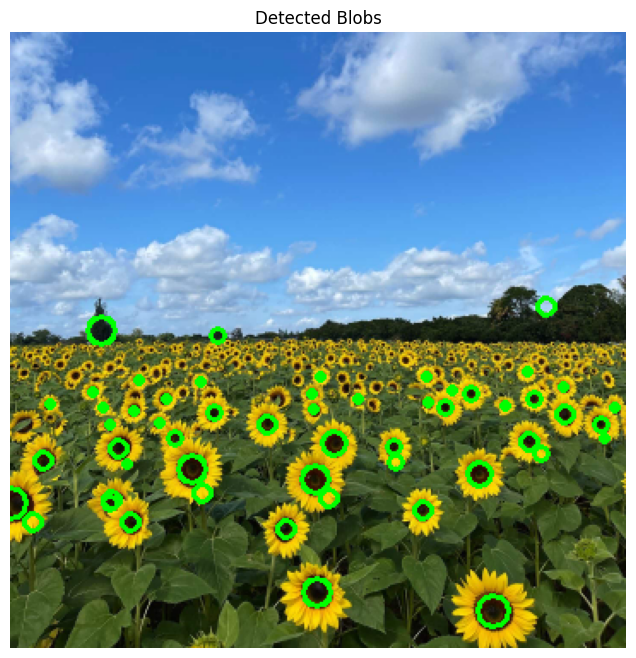

In [109]:
fig, ax = plt.subplots(1, s, figsize=(20,5))

scale_space_abs = np.abs(scale_space)
threshold_value = 70.0
binary_scale_space = scale_space_abs > threshold_value

for i in range(s):
    ax[i].set_title(r'$\sigma = {}$'.format(sigmas[i]))    
    ax[i].imshow(binary_scale_space[:,:,i], cmap = "gray")
    ax[i].axis('off')

local_max = maximum_filter(scale_space_abs, size=(3, 3, 3))
is_extrema = (scale_space_abs == local_max) & (scale_space_abs > threshold_value)

x_indices, y_indices, sigma_indices = np.where(is_extrema)

output_image = image_rgb.copy()

for x, y, s_idx in zip(x_indices, y_indices, sigma_indices):
    matched_sigma = sigmas[s_idx]
    radius = int(np.sqrt(2) * matched_sigma)
    cv.circle(output_image, (y, x), radius, (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(output_image, cv.COLOR_BGR2RGB))
plt.title(f"Detected Blobs")
plt.axis("off")
plt.show()

In [111]:
for i in range(s-1, -1, -1):
    if np.any(is_extrema[:, :, i]):
        found_layer_idx = i
        x_coords, y_coords = np.where(is_extrema[:, :, i])
        largest_scale_coordinates = list(zip(x_coords, y_coords))
        break
print(f"Center Coordinates of Largest Circles: {largest_scale_coordinates}")
print(f"Radius of the Largest Circle: {sigmas[i]*np.sqrt(2)} pixels")
print(f"Range of sigmas used: {sigmas}")

Center Coordinates of Largest Circles: [(275, 0), (338, 282)]
Radius of the Largest Circle: 9.899494936611665 pixels
Range of sigmas used: [ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]


The suitable gaussian kernel sizes and Threshold value of 70 are manually fine-tuned